# 01 — Aerial Image Formation in EUV Lithography

This notebook demonstrates how the aerial image is computed in euvsimulator:
1. **Mask → thin-mask diffraction orders**: analytic Fourier coefficients of the binary absorber/space reflectivity, as in the pipeline's default (`use_rcwa=True` switches to RCWA, see notebook 06)
2. **Multilayer Mirror → TMM**: Transfer-Matrix Method for Mo/Si stack reflectivity
3. **Hopkins Imaging**: Partial coherence + pupil filtering → aerial image

Key parameters:
- Wavelength: 13.5 nm (EUV)
- NA: 0.33 (standard) or 0.55 (High-NA)
- Partial coherence σ: 0.8 (conventional)
- Mask: Ta absorber on Mo/Si multilayer

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from euvsimulator.pipeline import SimulationConfig, run_simulation
from euvsimulator.aerial.abbe import aerial_from_orders, nils
from euvsimulator.optics.multilayer import mo_si_stack
from euvsimulator.optics.tmm import reflectivity
from euvsimulator.materials import CXROTable
from euvsimulator.resist.exposure import gaussian_se_blur

## 1. Configure Simulation

In [2]:
cfg = SimulationConfig(
    wavelength_nm=13.5,
    na=0.33,
    sigma=0.8,
    period_nm=64.0,
    line_width_nm=32.0,
    absorber_height_nm=60.0,
    absorber_material="Ta",
    n_rcwa_orders=21,
    dose_mj_cm2=20.0,
    grid=256,
    se_blur_nm=5.0,  # SE blur: used only by the full_chem chain (default 2.5 nm)
    device="cpu"
)

print(f"Period: {cfg.period_nm} nm")
print(f"Line width: {cfg.line_width_nm} nm")
print(f"NA: {cfg.na}, σ: {cfg.sigma}")
print(f"Grid: {cfg.grid}×{cfg.grid}")

Period: 64.0 nm
Line width: 32.0 nm
NA: 0.33, σ: 0.8
Grid: 256×256


## 2. Multilayer Mirror Reflectivity (TMM)

In [3]:
# Build Mo/Si multilayer stack
ml_stack = mo_si_stack(
    n_bilayers=50,
    d_mo_nm=2.8,
    d_si_nm=4.1,
    capping_layer="Ru",
    d_cap_nm=2.5
)

table = CXROTable()
n_si, k_si = table.refractive_index("Si", 91.84)
n_sub = torch.tensor(complex(n_si, k_si), dtype=torch.complex128)

# ML-only reflectivity (space regions)
wl = torch.tensor([13.5e-9], dtype=torch.float64)
theta = torch.tensor(np.radians(6.0), dtype=torch.float64)

_, r_space = reflectivity(
    ml_stack.n_layers,
    ml_stack.thicknesses,
    wl,
    theta,
    n_substrate=n_sub,
    roughness_nm=0.0
)
r0_space = r_space[0]

# Absorber-on-ML reflectivity
n_ta_c, k_ta_c = table.refractive_index("Ta", 91.84)
n_abs = torch.tensor(complex(n_ta_c, k_ta_c), dtype=torch.complex128)
d_abs = torch.tensor([60e-9], dtype=torch.float64)

full_n = torch.cat([n_abs.unsqueeze(0), ml_stack.n_layers])
full_d = torch.cat([d_abs, ml_stack.thicknesses])

_, r_ab = reflectivity(
    full_n,
    full_d,
    wl,
    theta,
    n_substrate=n_sub,
    roughness_nm=0.0
)
r0_abs = r_ab[0]

# Space reflectance at the ABSORBER-TOP plane. r0_abs refers to the absorber top,
# r0_space to the multilayer top, one absorber height lower; the thin-mask orders below
# add the two, so both must refer to one plane. A vacuum layer of the absorber height on
# top of the ML adds the round trip exp(2ikd cos θ) and leaves |r| unchanged
# (as pipeline.py does since 2026-10).
_, r_space_top = reflectivity(
    torch.cat([torch.ones(1, dtype=torch.complex128), ml_stack.n_layers]),
    torch.cat([d_abs, ml_stack.thicknesses]),
    wl,
    theta,
    n_substrate=n_sub,
    roughness_nm=0.0
)
r0_space_top = r_space_top[0]

print(f"Space reflectivity (|r|²): {abs(r0_space)**2:.4f}")
print(f"Absorber reflectivity (|r|²): {abs(r0_abs)**2:.4f}")
print(f"Phase difference at the absorber-top plane: {np.angle(r0_abs / r0_space_top):.3f} rad")

Space reflectivity (|r|²): 0.7322
Absorber reflectivity (|r|²): 0.0112
Phase difference at the absorber-top plane: -2.702 rad


## 3. Fourier Coefficients of Binary Complex Mask

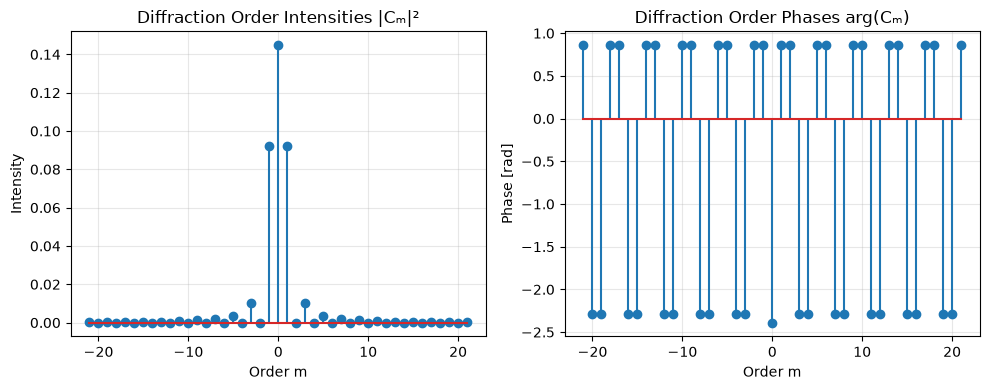

In [4]:
duty = cfg.line_width_nm / cfg.period_nm  # absorber fraction
n_orders = min(cfg.n_rcwa_orders, cfg.grid // 2)

a = r0_abs
b = r0_space_top  # same reference plane as a (the absorber top)
c0 = a * duty + b * (1.0 - duty)  # DC term

order_indices = list(range(-n_orders, n_orders + 1))
amplitudes = torch.zeros(len(order_indices), dtype=torch.complex128)

for idx, m in enumerate(order_indices):
    if m == 0:
        amplitudes[idx] = c0
    else:
        cm = (a - b) * np.sin(np.pi * m * duty) / (np.pi * m)
        amplitudes[idx] = cm

# Plot diffraction orders
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.stem(order_indices, (amplitudes.abs() ** 2).numpy())
ax1.set_title("Diffraction Order Intensities |Cₘ|²")
ax1.set_xlabel("Order m")
ax1.set_ylabel("Intensity")
ax1.grid(True, alpha=0.3)

ax2.stem(order_indices, amplitudes.angle().numpy())
ax2.set_title("Diffraction Order Phases arg(Cₘ)")
ax2.set_xlabel("Order m")
ax2.set_ylabel("Phase [rad]")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Aerial Image via Hopkins Formulation

In [5]:
order_tensor = torch.tensor(order_indices, dtype=torch.int64)
period_m = cfg.period_nm * 1e-9
wavelength_m = cfg.wavelength_nm * 1e-9

aerial = aerial_from_orders(
    amplitudes,
    order_tensor,
    period_m=period_m,
    na=cfg.na,
    wavelength_m=wavelength_m,
    sigma=cfg.sigma,
    illumination_shape="conventional",
    grid=cfg.grid,
)

# Normalise to the open frame, then scale by dose, as pipeline.py does: an absorber-free
# mask reflects |r_space|², so dividing by it makes an open frame expose the resist to
# exactly the dose, and aerial × dose is the local dose in mJ/cm². (Until 2026-10 this
# notebook skipped the division and showed 0.647 × the pipeline's values.)
R_clear = float(abs(r0_space) ** 2)
aerial = aerial / R_clear * cfg.dose_mj_cm2

print(f"Aerial image shape: {aerial.shape}")
print(f"Max intensity: {aerial.max():.3f} mJ/cm²")
print(f"Min intensity: {aerial.min():.3f} mJ/cm²")
# Note (corrected 2026-09-04): aerial_from_orders() no longer accepts se_blur_nm --
# SE blur was moved out of the aerial-image (pure optics) step into the resist step,
# where it physically belongs (secondary-electron transport is a resist effect, not
# an imaging effect). cfg.se_blur_nm is therefore unused by this pure-optics notebook.


Aerial image shape: torch.Size([256, 256])
Max intensity: 18.033 mJ/cm²
Min intensity: 0.692 mJ/cm²


## 5. Visualize Aerial Image

NILS at line edge: 4.831


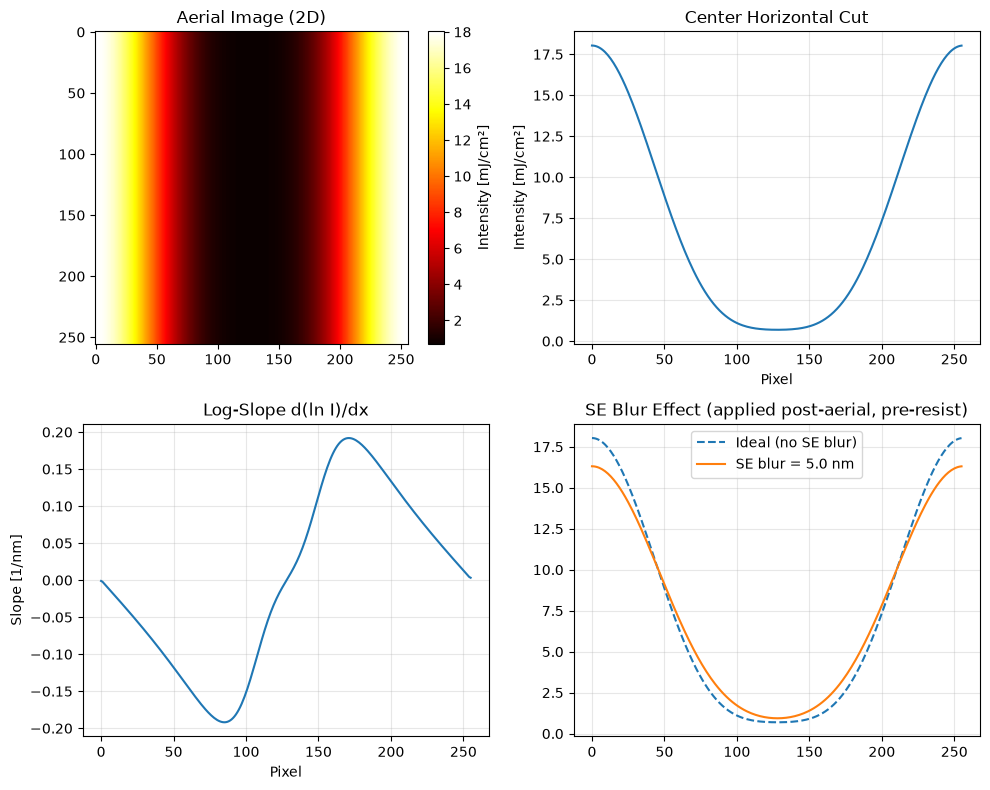

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

# Full 2D aerial image
im1 = axes[0,0].imshow(aerial.numpy(), cmap="hot", aspect="equal")
axes[0,0].set_title("Aerial Image (2D)")
plt.colorbar(im1, ax=axes[0,0], label="Intensity [mJ/cm²]")

# Center cut
half = cfg.grid // 2
cut = aerial[half, :].numpy()
axes[0,1].plot(cut)
axes[0,1].set_title("Center Horizontal Cut")
axes[0,1].set_xlabel("Pixel")
axes[0,1].set_ylabel("Intensity [mJ/cm²]")
axes[0,1].grid(True, alpha=0.3)

# Log-slope (NILS)
dx_nm = cfg.period_nm / cfg.grid
line_width_px = int(round(cfg.line_width_nm / dx_nm))
nils_val = nils(aerial, half, line_width_px, dx_nm)
print(f"NILS at line edge: {nils_val:.3f}")

# Compute log-slope profile
log_aerial = torch.log(aerial + 1e-12)
log_slope = torch.gradient(log_aerial[half, :], spacing=dx_nm)[0]
axes[1,0].plot(log_slope.numpy())
axes[1,0].set_title("Log-Slope d(ln I)/dx")
axes[1,0].set_xlabel("Pixel")
axes[1,0].set_ylabel("Slope [1/nm]")
axes[1,0].grid(True, alpha=0.3)

# SE blur effect comparison.
# Note (corrected 2026-09-04): aerial_from_orders() no longer applies SE blur
# internally (moved to the resist step, where it physically belongs -- see the
# note in the previous cell). To reproduce this comparison, apply
# gaussian_se_blur() directly to the (unblurred) aerial dose map -- this is
# exactly the same call pipeline.py itself makes just before the resist chain
# (dose_map_blurred = gaussian_se_blur(dose_map, sigma=cfg.se_blur_nm, dx=dx_nm)),
# so this panel now shows the real pipeline step, not an aerial-image-internal one.
aerial_blurred = gaussian_se_blur(aerial, sigma=cfg.se_blur_nm, dx=dx_nm)

axes[1,1].plot(aerial[half, :].numpy(), label="Ideal (no SE blur)", linestyle="--")
axes[1,1].plot(aerial_blurred[half, :].numpy(), label=f"SE blur = {cfg.se_blur_nm} nm")
axes[1,1].set_title("SE Blur Effect (applied post-aerial, pre-resist)")
axes[1,1].legend()
axes[1,1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 6. NA and σ Sensitivity

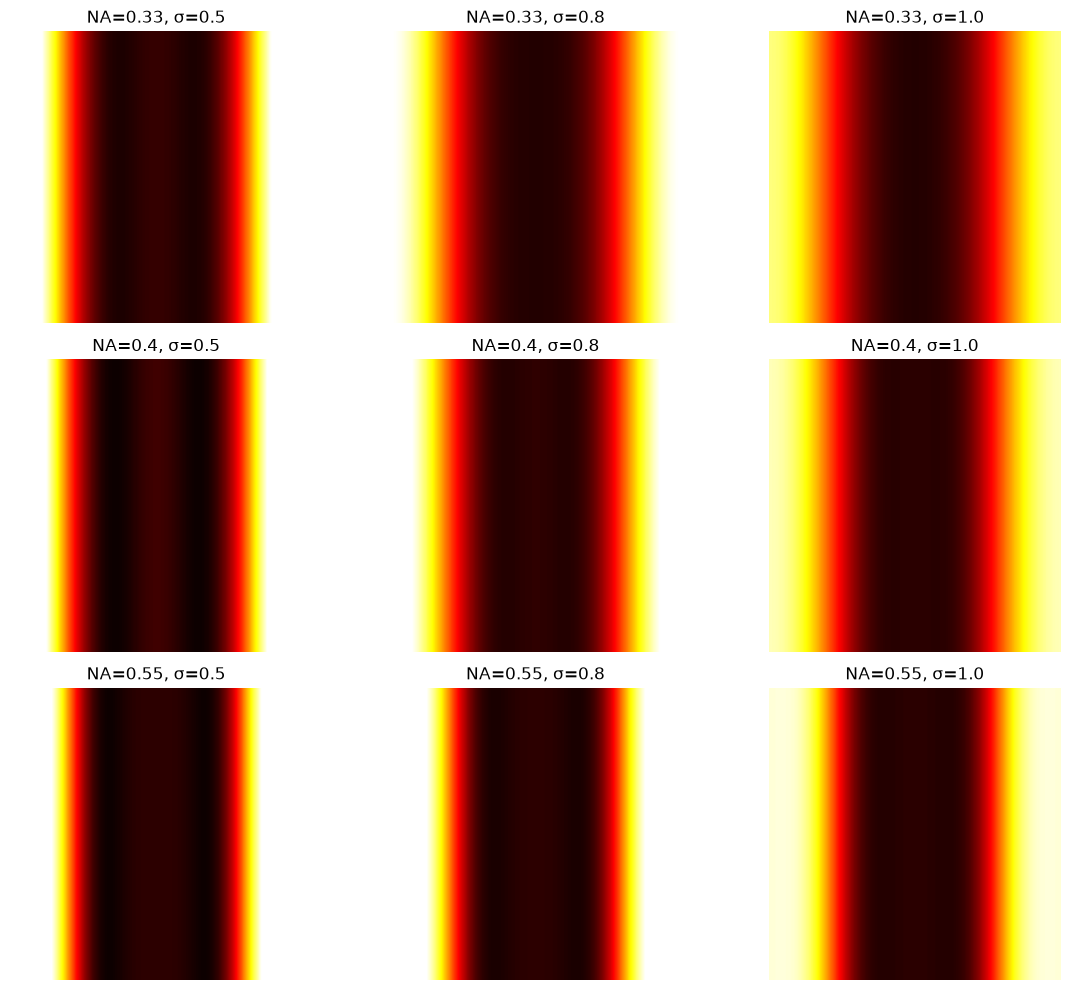

In [7]:
nas = [0.33, 0.40, 0.55]  # Standard, improved, High-NA
sigmas = [0.5, 0.8, 1.0]  # partial-coherence factor (coherent would be σ → 0)

fig, axes = plt.subplots(len(nas), len(sigmas), figsize=(12, 10), sharex=True, sharey=True)

for i, na in enumerate(nas):
    for j, sigma in enumerate(sigmas):
        aerial_test = aerial_from_orders(
            amplitudes, order_tensor,
            period_m=period_m, na=na, wavelength_m=wavelength_m,
            sigma=sigma, illumination_shape="conventional",
            grid=cfg.grid
        ) / R_clear * cfg.dose_mj_cm2
        
        im = axes[i,j].imshow(aerial_test.numpy(), cmap="hot", aspect="equal", vmin=0, vmax=aerial.max())
        axes[i,j].set_title(f"NA={na}, σ={sigma}")
        axes[i,j].axis("off")

plt.tight_layout()
plt.show()

## 7. Run Full Pipeline for Comparison

In [8]:
result = run_simulation(cfg)

print(f"CD: {result.cd_nm:.2f} nm")
print(f"NILS: {result.nils_value:.3f}")
print(f"Absorber reflectivity: {result.absorber_reflectivity:.4f} "
      f"(this notebook: {abs(r0_abs)**2:.4f})")
print(f"Max intensity: {result.aerial_image.max():.3f} mJ/cm² (this notebook: {aerial.max():.3f})")

CD: 27.29 nm
NILS: 4.831
Absorber reflectivity: 0.0112 (this notebook: 0.0112)
Max intensity: 18.033 mJ/cm² (this notebook: 18.033)


## Summary

- **Diffraction orders** carry amplitude & phase info from the complex mask
- **Hopkins formulation** accounts for partial coherence (σ) and pupil (NA)
- **SE blur** lowers the image contrast; notebook 02 quantifies it on this image (NILS 4.50 → 3.30 at 5 nm)
- **NILS** quantifies edge steepness — higher = better process window
- **High NA (0.55)** resolves smaller features; this model uses an isomorphic pupil (the anamorphic 4×/8× high-NA optics is not included)